# Evaluation 4 – Correctness (manual check)

Every answer was checked by hand in notebook 03: the answer was compared with SQL run on both databases
and marked **correct**, **partly** correct or **wrong**. Asks that gave the same answer share one verdict.

This notebook shows the result first, then goes through each model and explains, step by step, why an answer was
not correct.

**Data:** 4 models × 100 questions × 2 agents × 5 repetitions = 4 000 asks (1 000 per model).

In [19]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)

DATA_DIR = Path("..") / "data"
VERDICT_FILE = Path("..") / "review" / "answer_verdicts_per_ask.csv"
OUT_DIR = Path("outputs") / "04_correctness"
OUT_DIR.mkdir(parents=True, exist_ok=True)

MODELS = ["gpt-4o-mini", "claude-haiku", "qwen3-8b", "qwen3-8b-lora"]
MODEL_LABEL = {"gpt-4o-mini": "GPT-4o mini", "claude-haiku": "Claude Haiku 5.5",
               "qwen3-8b": "Qwen3-8B", "qwen3-8b-lora": "Qwen3-8B + QLoRA"}
VERDICTS = ["correct", "partly", "wrong"]
VERDICT_COLOR = {"correct": "#0ca30c", "partly": "#fab219", "wrong": "#d03b3b"}

# the question text for each question id
files = [f for f in DATA_DIR.glob("evaluation_per_model_runs-*/evaluation_*_runs-*.csv") if "summary" not in f.name]
questions = (pd.concat([pd.read_csv(f, encoding="utf-8-sig", usecols=["qid", "question"]) for f in files])
               .drop_duplicates("qid").set_index("qid")["question"])

df = pd.read_csv(VERDICT_FILE, encoding="utf-8-sig")
df["model"] = pd.Categorical(df["model"], categories=MODELS, ordered=True)
print(f"{len(df)} asks, {df['qid'].nunique()} questions, verdicts: {df['verdict_manual'].value_counts().to_dict()}")

4000 asks, 100 questions, verdicts: {'correct': 3836, 'wrong': 94, 'partly': 70}


## 1. Result of the manual check

In [20]:
result = pd.crosstab(df["model"], df["verdict_manual"]).reindex(columns=VERDICTS, fill_value=0)
result["correct %"] = result["correct"] / result[VERDICTS].sum(axis=1) * 100
result.rename(index=MODEL_LABEL)

verdict_manual,correct,partly,wrong,correct %
model,,,,
GPT-4o mini,931,35,34,93.1
Claude Haiku 5.5,975,15,10,97.5
Qwen3-8B,965,5,30,96.5
Qwen3-8B + QLoRA,965,15,20,96.5


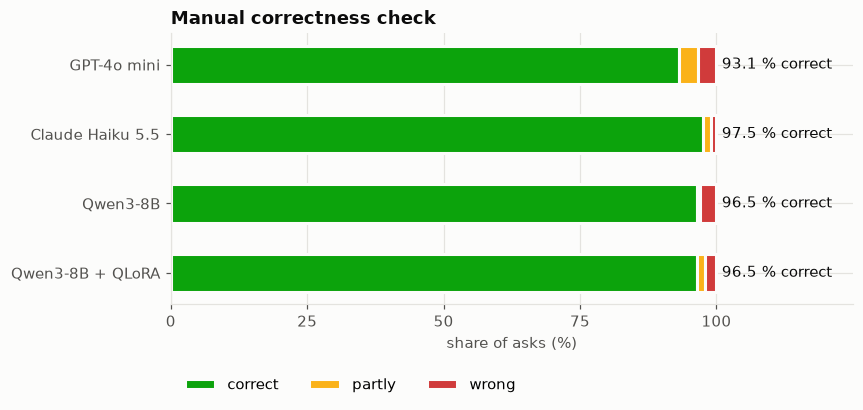

In [21]:
share = result[VERDICTS].div(result[VERDICTS].sum(axis=1), axis=0) * 100
fig, ax = plt.subplots(figsize=(8, 3.2), facecolor="#fcfcfb")
ax.set_facecolor("#fcfcfb")
y = np.arange(len(MODELS))[::-1]
left = np.zeros(len(MODELS))
for v in VERDICTS:
    ax.barh(y, share.loc[MODELS, v], left=left, height=0.55, color=VERDICT_COLOR[v], label=v,
            edgecolor="#fcfcfb", linewidth=2)
    left += share.loc[MODELS, v].values
for yi, m in zip(y, MODELS):
    ax.text(101, yi, f"{share.loc[m, 'correct']:.1f} % correct", va="center", color="#0b0b0b")
ax.set_yticks(y, [MODEL_LABEL[m] for m in MODELS])
ax.set_xlim(0, 125)
ax.set_xticks([0, 25, 50, 75, 100])
ax.set_xlabel("share of asks (%)")
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.set_title("Manual correctness check", loc="left", fontweight="bold")
ax.legend(ncol=3, loc="upper left", bbox_to_anchor=(0, -0.22), frameon=False)
fig.savefig(OUT_DIR / "manual_correctness.png", dpi=300, bbox_inches="tight")
plt.show()

In [22]:
def not_correct(model):
    # The answers of one model that are not fully correct: one row per question and agent.
    d = df[(df["model"] == model) & (df["verdict_manual"] != "correct")]
    t = (d.groupby(["qid", "agent_name", "verdict_manual"]).size().rename("asks").reset_index()
          .pivot_table(index=["qid", "verdict_manual"], columns="agent_name", values="asks", fill_value=0)
          .astype(int))
    t.columns = [f"{c} asks" for c in t.columns]
    t = t.reset_index()
    t.insert(1, "question", t["qid"].map(questions))
    return t.rename(columns={"verdict_manual": "verdict"})

## 2. GPT-4o mini – 931 correct, 35 partly, 34 wrong

In [23]:
not_correct("gpt-4o-mini")

,qid,question,verdict,Agent-001 asks,Agent-002 asks
0,t017,Population of Bavaria in 2030,wrong,2,2
1,t023,Where is Freiburg im Breisgau located?,wrong,5,5
2,t025,"Shapes of Kiel, Lübeck and Rostock",partly,5,5
3,t030,Where is Görlitz?,wrong,5,5
4,t051,Which cities lie north of Baden-Württemberg?,partly,5,0
5,t053,What cities are south of Niedersachsen?,partly,5,0
6,t056,Which cities are in Baden-Württemberg?,partly,5,0
7,t069,Which state borders both Sachsen and Bayern?,partly,5,5
8,t093,Which states lie within 60 km of Frankfurt am Main?,wrong,5,5


**t023 Freiburg im Breisgau, t030 Görlitz – wrong (20 asks)**
1. The question "Where is … ?" was classified as **UNRELATED** instead of GEOMETRY_LOOKUP.
2. Because the question was judged out of scope, the agent rejected it at once.
3. So no SQL and no KQML ran, and no point was returned – although the city is in the database
   (Agent-002 has it; Agent-001 could have asked for it).

**t017 Population of Bavaria in 2030 – wrong (4 of 10 asks)**
1. In 4 asks the year **2030 was dropped** during extraction (probably because it lies in the future).
2. Without a year the agent could not build the query and asked for one (status *rejected*).
3. The other 6 asks kept the year, searched both databases and correctly answered *not found*.

**t025 Shapes of Kiel, Lübeck and Rostock – partly (10 asks)**
1. The question was classified as **SPATIAL_OPERATION** instead of GEOMETRY_LOOKUP.
2. So the SQL merged the three cities into one shape (MULTIPOINT).
3. The three points are exactly right, but the city names are lost – the user cannot tell which point is which.

**t069 State bordering both Sachsen and Bayern – partly (10 asks)**
1. The SQL written by GPT-4o mini returned **Thüringen twice**.
2. This happens on both agents, also on Agent-002 without any KQML exchange, so it comes from the SQL itself.
3. The state is right, but the list has a duplicate.

**t051, t053, t056 City lists on Agent-001 – partly (15 asks)**
1. Agent-001 holds only part of the cities, so it asks Agent-002 via KQML for the rest and sends the
   names it already has (*exclude list*) so they are not sent twice.
2. The exclude list contains **names only**. Germany has several cities with the same name (Essen, Münster,
   Weingarten, …), so a city in Agent-001 with that name also excluded the other, different city in Agent-002.
3. The answer misses those cities: 5 of 1 195 (t051), 6 of 1 075 (t053), 1 of 281 (t056).
   Agent-002 has all cities itself and answers completely.

**t093 States within 60 km of Frankfurt am Main – wrong (10 asks)**
1. The databases store the city as **"Frankfurt"**, not "Frankfurt am Main".
2. Neither agent found the name – the KQML reply was *shape not found* – so there was no reference point.
3. Without the point no distance could be computed, and the answer was **0 states**. Correct is
   Hessen, Bayern, Rheinland-Pfalz and Baden-Württemberg.

## 3. Claude Haiku 5.5 – 975 correct, 15 partly, 10 wrong

In [24]:
not_correct("claude-haiku")

,qid,question,verdict,Agent-001 asks,Agent-002 asks
0,t051,Which cities lie north of Baden-Württemberg?,partly,5,0
1,t053,What cities are south of Niedersachsen?,partly,5,0
2,t056,Which cities are in Baden-Württemberg?,partly,5,0
3,t093,Which states lie within 60 km of Frankfurt am Main?,wrong,5,5


Claude Haiku made **no model error**: classification, extraction and SQL were right in every case that went wrong.
Both problems come from the system:

**t051, t053, t056 City lists on Agent-001 – partly (15 asks)**
1. Agent-001 asked Agent-002 for the missing cities and excluded the names it already had.
2. Because the exclude list uses names only, same-name cities were wrongly excluded.
3. A few cities are missing (5, 6 and 1). Same cause as for GPT-4o mini.

**t093 Frankfurt am Main – wrong (10 asks)**
1. "Frankfurt am Main" is stored as "Frankfurt", so the name was not found in either database.
2. No reference point → no distance → **0 states** instead of 4.

## 4. Qwen3-8B – 965 correct, 5 partly, 30 wrong

In [25]:
not_correct("qwen3-8b")

,qid,question,verdict,Agent-001 asks,Agent-002 asks
0,t051,Which cities lie north of Baden-Württemberg?,wrong,5,0
1,t053,What cities are south of Niedersachsen?,wrong,5,0
2,t056,Which cities are in Baden-Württemberg?,partly,5,0
3,t093,Which states lie within 60 km of Frankfurt am Main?,wrong,5,5
4,t094,Give me the live births in 2016 of the states within 100 km of Kassel,wrong,5,5


**t094 Live births 2016 of the states within 100 km of Kassel – wrong (10 asks)**
1. The question was classified as **SPATIAL_OPERATION** instead of SPATIAL_DISTANCE.
2. The SQL then used a placeholder for the year (`:year`) that the agent does not provide.
3. The SQL failed the check in all 4 attempts, so the answer ended with status **error** and no data.

**t051, t053 City lists on Agent-001 – wrong (10 asks)**
1. Agent-001 asked Agent-002 for the missing cities (a large request: about 600 names to exclude).
2. Agent-002 answered **HTTP 500** (server error) three times – this happened only in the Qwen runs.
3. Agent-001 kept only its own cities (606 of 1 195, 528 of 1 075) **but still reported the answer as complete** –
   the user is not told that half the data is missing.

**t056 Cities in Baden-Württemberg on Agent-001 – partly (5 asks)**
1. Same exclude-list problem as for the other models: one Weingarten was excluded by name.

**t093 Frankfurt am Main – wrong (10 asks)**
1. Name not found ("Frankfurt" in the database) → no reference point → 0 states.

## 5. Qwen3-8B + QLoRA – 965 correct, 15 partly, 20 wrong

In [26]:
not_correct("qwen3-8b-lora")

,qid,question,verdict,Agent-001 asks,Agent-002 asks
0,t029,Boundaries of all German federal states,partly,5,5
1,t051,Which cities lie north of Baden-Württemberg?,wrong,5,0
2,t053,What cities are south of Niedersachsen?,wrong,5,0
3,t056,Which cities are in Baden-Württemberg?,partly,5,0
4,t093,Which states lie within 60 km of Frankfurt am Main?,wrong,5,5


Fine-tuning fixed the base model's error on **t094** (Kassel): the QLoRA model classified it correctly and answered it.
It made one new error of its own:

**t029 Boundaries of all German federal states – partly (10 asks)**
1. During extraction the model wrote **"Mecklenburg-Vorpowell"** instead of Mecklenburg-Vorpommern.
2. The agent did not find that name locally and asked the other agent via KQML, which did not find it either.
3. The answer has 15 of the 16 states, and the 16th is reported as missing.

**t051, t053 City lists on Agent-001 – wrong (10 asks)**
1. As for the base model: Agent-002 answered HTTP 500 three times.
2. Agent-001 returned only its own cities but reported the answer as complete.

**t056 – partly (5 asks)** and **t093 – wrong (10 asks)**: the same system problems as for all models
(exclude list by name; "Frankfurt am Main" not found).

## 6. Summary

| cause | step | GPT-4o mini | Claude Haiku | Qwen3-8B | Qwen + QLoRA |
|---|---|---|---|---|---|
| "Where is …?" rejected as UNRELATED | classify (model) | 20 | – | – | – |
| wrong query type | classify (model) | 10 | – | 10 | – |
| year dropped / place-name typo | extract (model) | 4 | – | – | 10 |
| SQL returned a duplicate | SQL (model) | 10 | – | – | – |
| "Frankfurt am Main" not found | name lookup (system) | 10 | 10 | 10 | 10 |
| exclude list uses names only | KQML (system) | 15 | 15 | 5 | 5 |
| peer failed (HTTP 500), still "complete" | KQML (system) | – | – | 10 | 10 |
| **asks not fully correct** | | **69** | **25** | **35** | **35** |

Every model has the same **25 asks** lost to system problems (name lookup and KQML). The rest are model errors:
44 for GPT-4o mini, 10 for each Qwen model and none for Claude Haiku.

In [ ]:
with pd.ExcelWriter(OUT_DIR / "manual_correctness.xlsx") as xl:
    result.rename(index=MODEL_LABEL).round(2).to_excel(xl, sheet_name="result")
    for m in MODELS:
        not_correct(m).to_excel(xl, sheet_name=MODEL_LABEL[m][:31].replace("+", "plus"), index=False)
print("saved to", OUT_DIR)